# PPKS 03: Implementacija konvolucije i korelacije

***

Konvolucija i korelacija su jedne od najvažnijih operacija u digitalnoj obradi signala. U nastavku ćemo vidjeti zašto je to tako i gdje se sve koriste, ali prije matematičkih izraza, pogledajmo sljedeće primjere.

***
__Primjer 1__

Recimo da imamo ulazni signal  $x[n]$. Napravimo sad kopiju tog signala koja je zakašnjela za $k$ uzoraka: $x[n-k]$.

Ako sada zbrojimo originalni signal i njegovu pomaknutu kopiju, dobivamo novi signal

$$
y[n] = x[n] + x[n-k]
$$

To znači da se svaki izlazni uzorak računa kao zbroj vrijednosti trenutnog uzorka ulaza $x[n]$ i vrijednosti uzorka koji se dogodio $k$ trenutaka ranije $x[n-k]$

__Implementacija__

Na primjeru ulaznog diskretnog signala čiji se period sastoji od šest uzoraka vrijednosti '1' i šest uzoraka vrijednosti '-1', odnosno $x[n]=[1,1,1,1,1,1,-1,-1,-1,-1,-1,-1...]$ u programu u nastavku možemo pratiti kako se mijenja $y[n]$ za različite iznose kašnjenja $k$.

Ono što se može primijetiti je da se $y[n]$ periodički ponavlja od trenutka $k$ (za $k\gt 0$). Vrijeme prije nego se izlazni signal počne periodički ponavljati nazivamo __warm up__ fazom.








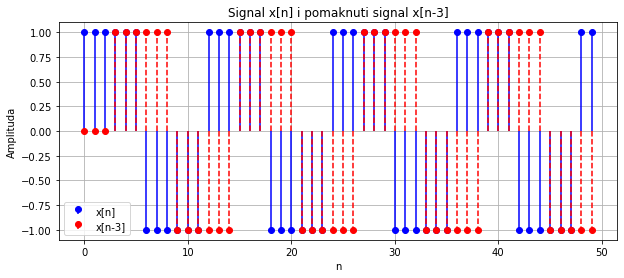

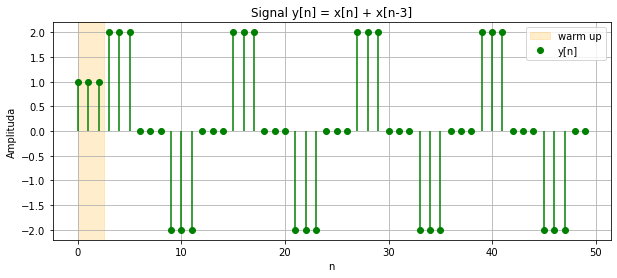

In [42]:
import numpy as np
import matplotlib.pyplot as plt

N = 50  # broj uzoraka 
period = 12

one_period = np.array([1]*6 + [-1]*6)

# Generiranje periodičnog signala kojem se ponavlja period s 6 uzoraka [1] i 6 uzoraka [-1]
x = np.tile(one_period, N // period + 1)[:N]

delay = 3
x_delayed = np.zeros_like(x)
x_delayed[delay:] = x[:-delay]   # x[n-3]

# Izlazni signal
y = x + x_delayed

n = np.arange(N)

plt.figure(figsize=(10,4))
plt.stem(n, x, linefmt='b-', markerfmt='bo', basefmt=" ", label='x[n]')
plt.stem(n, x_delayed, linefmt='r--', markerfmt='ro', basefmt=" ", label=f"x[n-{delay}]")
plt.title(f'Signal x[n] i pomaknuti signal x[n-{delay}]')
plt.xlabel('n')
plt.ylabel('Amplituda')
plt.legend()
plt.grid(True)

plt.figure(figsize=(10,4))
plt.stem(n, y, linefmt='g-', markerfmt='go', basefmt=" ", label="y[n]")
plt.axvspan(0, delay-0.5, alpha=0.2, color='orange', label="warm up")
plt.title(f'Signal y[n] = x[n] + x[n-{delay}]')
plt.xlabel('n')
plt.ylabel('Amplituda')
plt.legend()
plt.grid(True)

plt.show()

***
__Primjer 2__

Sada možemo napraviti općenitiji primjer.
Umjesto da samo zbrajamo dvije kopije signala, možemo svaku kopiju i **skalirati** nekim koeficijentom:

$$
y[n] = \frac{1}{2}x[n] - \frac{1}{2}x[n-1]
$$

Što se zapravo događa s izlaznim signalom?

Ovdje postoje dvije kopije ulaznog signala:

- $x[n]$ ima pojačanje $+1/2$
- $x[n-1]$ ima pojačanje $-1/2$

Ako su vrijednosti dva uzastopna uzorka signala jednaka, tada vrijedi $x[n] = x[n-1]$
pa dobivamo

$y[n] = \frac{1}{2}x[n] - \frac{1}{2}x[n] = 0$

Zato će izlaz biti nula kada se signal ne mijenja. Odnosno, izlaz će biti različit od nule samo kada se signal mijenja između dva uzorka. 

__Implementacija__

Pogledajmo kako to izgleda na primjeru ulaznog signala iz prošlog zadatka. Vidimo da izlazni signal ima vrijednost $\ne0$ samo u trenucima kad se signal $x[n]$ mijenja. Izlazni signal predznacima tih vrijednosti pokazuje smjer promjene.



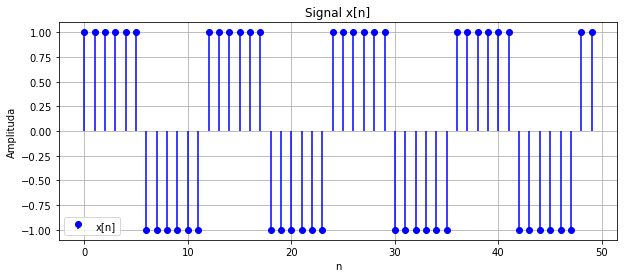

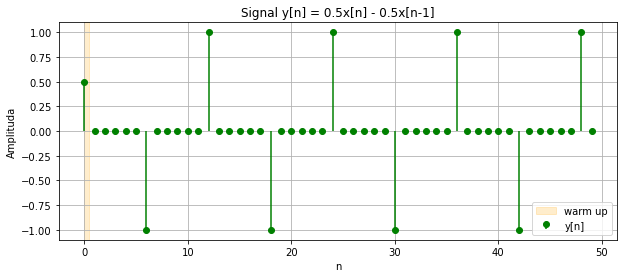

In [41]:
import numpy as np
import matplotlib.pyplot as plt

N = 50  # broj uzoraka 
period = 12

one_period = np.array([1]*6 + [-1]*6)

# Generiranje periodičnog signala kojem se ponavlja period s 6 uzoraka [1] i 6 uzoraka [-1]
x = np.tile(one_period, N // period + 1)[:N]

delay = 1
x_delayed = np.zeros_like(x)
x_delayed[delay:] = x[:-delay]   

# Izlazni signal
y = 0.5*x -0.5*x_delayed

n = np.arange(N)

plt.figure(figsize=(10,4))
plt.stem(n, x, linefmt='b-', markerfmt='bo', basefmt=" ", label='x[n]')
plt.title(f'Signal x[n]')
plt.xlabel('n')
plt.ylabel('Amplituda')
plt.legend()
plt.grid(True)

plt.figure(figsize=(10,4))
plt.stem(n, y, linefmt='g-', markerfmt='go', basefmt=" ", label="y[n]")
plt.axvspan(0, delay-0.5, alpha=0.2, color='orange', label="warm up")
plt.title(f'Signal y[n] = 0.5x[n] - 0.5x[n-{delay}]')
plt.xlabel('n')
plt.ylabel('Amplituda')
plt.legend()
plt.grid(True)

plt.show()

***
## Konvolucija

__Konvolucija__ je operacija koja pomoću signala $x[n]$ i $h[n]$ računa izlazni signal $y[n]$ na sljedeći način:

$$
y[n] = \sum_{k=-\infty}^{\infty} x[k]\,h[n-k]
$$

U pravilu ćemo $x[n]$ zvati ulaznim signalom, $h[n]$ jezgrom ili filtrom, a $y[n]$ izlaznim signalom. 

Za konvoluciju ćemo koristiti znak $*$ pa možemo reći da je signal $y$ rezultat konvolucije signala $x$ i $h$:

$$
y=x*h
$$

***

__Zašto su važni prethodni primjeri?__

Kasnije ćemo pokazati da je jedno od svojstava konvolucije komutativnost što znači da je svejedno računamo li $y[n] = \sum_{k=-\infty}^{\infty} x[k]\,h[n-k]$ ili 

$y[n] = \sum_{k=-\infty}^{\infty} h[k]\,x[n-k]$ 

pa ćemo zbog jednostavnijeg shvaćanja za početak promatrati drugi pristup i pojednostaviti ga uzimanjem u obzir da $x[n]$ ima $N$ uzoraka, a $h[n]$ $K$ uzoraka.

Ako raspišemo tu sumu dobit ćemo sljedeće:

$y[n] = \sum_{k=0}^{K-1} h[k]\,x[n-k]$

$y[n] = h[0] \cdot x[n-0]+ h[1] \cdot x[n-1]+h[2] \cdot x[n-2]+ \dots + h[K-1] \cdot x[n-(K-1)]$

Ono što možemo uočiti jest da se konvolucija svodi na iste operacije kao i prethodni primjeri: pomicanje (kašnjenje), skaliranje i zbrajanje signala. Konkretno, svaki član sume predstavlja pomaknuti signal $x[n-k]$ pomnožen s odgovarajućim koeficijentom $h[k]$, a zatim se svi ti članovi zbrajaju.
Drugim riječima, svaki uzorak izlaznog signala $y[n]$ dobiva se kao težinska suma određenog dijela ulaznog signala $x[n]$, gdje su težine zadane koeficijentima $h[k]$.

__Primjer 1 konvolucijom__

Pogledajmo opet Primjer 1 s početka poglavlja.
Ako filtru zadamo vrijednosti $h[n]=[1,0,0,1]$, za ulazni signal iz tog primjera, njihovom konvolucijom ($y=x*h$) dobit ćemo isti $y[n]$ kao kada smo ga računali s

$y[n] = x[n] + x[n-3]$

To je zato jer skaliramo $x[n-0]$ s vrijednosti koja je u $h[0]$ (dakle 1) i $x[n-3]$ s vrijednosti koja je u $h[3]$ (opet 1) dok je vrijednost filtra na ostalim uzorcima jednaka nuli. Konvolucija ulaznog signala s tim filtrom dana je u sljedećoj implementaciji:




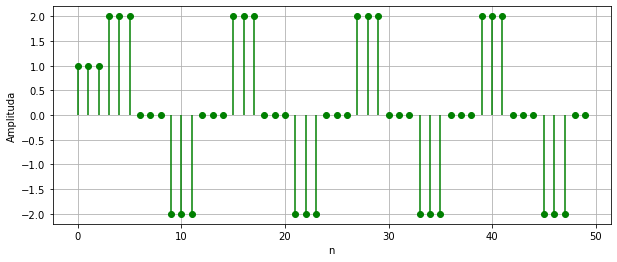

In [50]:
import numpy as np
import matplotlib.pyplot as plt

N = 50
period = 12

one_period = np.array([1]*6 + [-1]*6)
x = np.tile(one_period, N // period + 1)[:N]

h = [1,0,0,1]

y_conv = np.convolve(x, h)

y_conv = y_conv[:N] # prikazi samo prvih N uzoraka

n = np.arange(N)

plt.figure(figsize=(10,4))
plt.stem(n, y_conv, linefmt='g-', markerfmt='go', basefmt=" ", label='y[n]')
plt.grid(True)
plt.xlabel('n')
plt.ylabel('Amplituda')

plt.show()

***
### Konvolucija kao alat za filtriranje signala

Važnost konvolucije postaje jasnija kada vidimo da njome možemo implementirati i vrlo jednostavne operacije koje već dobro poznajemo.

Primjerice, ako signal želimo samo __pojačati__, dovoljno je svaki njegov uzorak pomnožiti s konstantom, što se može napraviti konvoluiranjem s filtrom u kojem je jedan uzorak ta konstanta (označimo ju s $G$), odnosno $h[n]=[G]$. Isto tako, ako signal želimo __zakasniti__ za $d$ uzoraka, možemo ga konvoluirati s filtrom koji ima $d$ nula ispred jedne jedinice ($h[n]=[0,0,0,...,0,1]$). To su operacije koje je vrlo lako implementirati direktno. Međutim, ono što je važno jest da se obje mogu opisati konvolucijom uz odgovarajući izbor signala filtra $h[n]$. Ako gledamo korak dalje, konvolucija pruža mogućnost ujedinjavanja više različitih operacija nad signalima.

Na primjer, pojačanje i kašnjenje ne moramo promatrati kao dvije odvojene operacije, već ih možemo objediniti u jedan filtar. Time se složeniji sustavi grade na potpuno isti način kao i najjednostavniji, što značajno pojednostavljuje analizu i dizajn.

U nastavku je dan primjer u kojem je isti ulazni signal obrađen na tri načina: samo pojačanjem, samo kašnjenjem te kombinacijom pojačanja i kašnjenja. Važno je uočiti da se u sva tri slučaja koristi samo konvolucija dok se ponašanje sustava mijenja isključivo promjenom filtra $h[n]$.

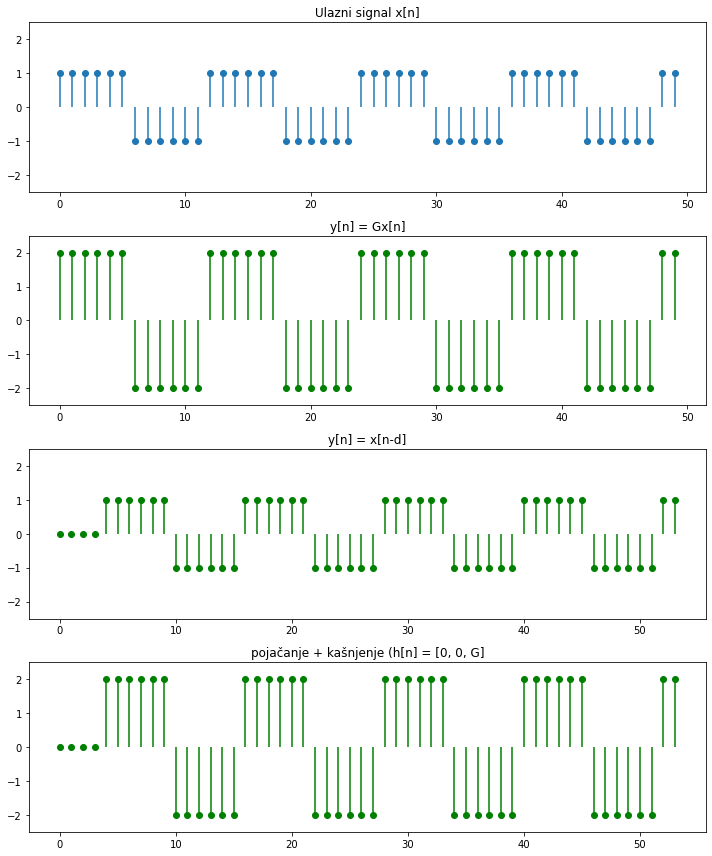

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# isti signal kao prije
one_period = np.array([1]*6 + [-1]*6)
x = np.tile(one_period, N // period + 1)[:N]

h_gain = [2] # gain = 2
y_gain = np.convolve(x, h_gain)


d = 4 # zelimo zakasniti signal za 4 uzorka
h_delay = np.zeros(d + 1)
h_delay[-1] = 1
y_delay = np.convolve(x, h_delay)


G=2
h_combined = np.zeros(d + 1)
h_combined[-1] = G   # [0, 0, G]
y_combined = np.convolve(x, h_combined)


plt.figure(figsize=(10, 12))

# ulaz
plt.subplot(4, 1, 1)
plt.stem(x, basefmt=" ")
plt.ylim(-2.5, 2.5)
plt.title("Ulazni signal x[n]")

# gain
plt.subplot(4, 1, 2)
plt.stem(y_gain, linefmt='g-', markerfmt='go', basefmt=" ")
plt.ylim(-2.5, 2.5)
plt.title("y[n] = Gx[n]")

# delay
plt.subplot(4, 1, 3)
plt.stem(y_delay, linefmt='g-', markerfmt='go', basefmt=" ")
plt.ylim(-2.5, 2.5)
plt.title("y[n] = x[n-d]")

# kombinacija
plt.subplot(4, 1, 4)
plt.stem(y_combined, linefmt='g-', markerfmt='go', basefmt=" ")
plt.ylim(-2.5, 2.5)
plt.title("pojačanje + kašnjenje (h[n] = [0, 0, G]")

plt.tight_layout()
plt.show()

***
### Programska implementacija konvolucije

U programskoj implementaciji konvoluciju možemo izvesti pomoću dvije petlje:

    za svaki n:

        suma = 0

        za svaki k:

            suma += x[k] * h[n-k]

        y[n] = suma

U nastavku je prikazana implementacija konvolucije na primjeru signala $x[n]=-1,2,1$ i $h[n]=2,1$

In [2]:
x = {0:-1, 1:2, 2:1}
h = {0:2, 1:1}

print("x[n] =", x)
print("h[n] =", h)

y = {}

for n in range(0, 4):
    s = 0
    for k in x:
        if (n-k) in h:
            s = s + x[k]*h[n-k]
    y[n] = s

    
print("y[n] =", y)

x[n] = {0: -1, 1: 2, 2: 1}
h[n] = {0: 2, 1: 1}
y[n] = {0: -2, 1: 3, 2: 4, 3: 1}


NumPy rezultat : [-2  3  4  1]
SciPy rezultat : [-2  3  4  1]

Koraci konvolucije:


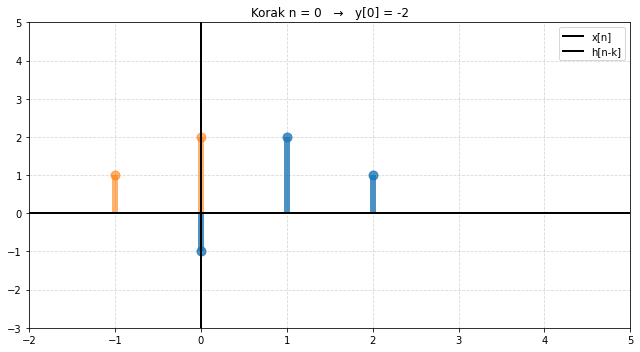

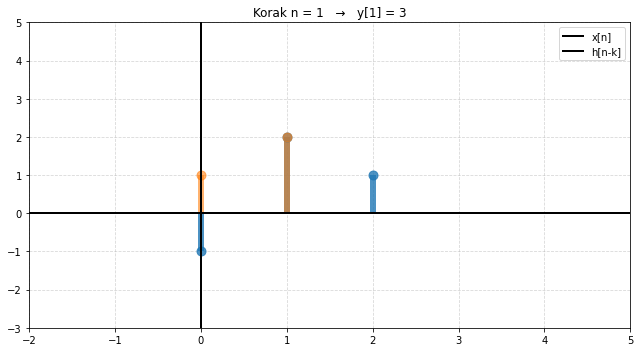

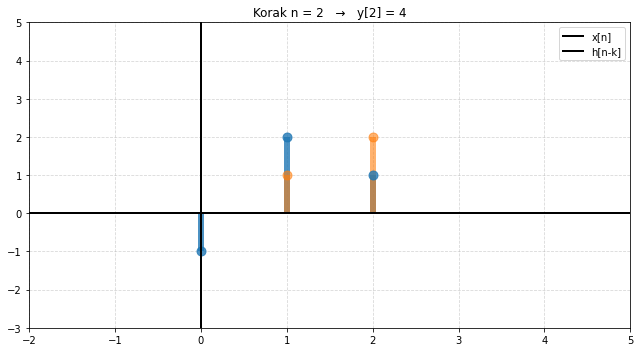

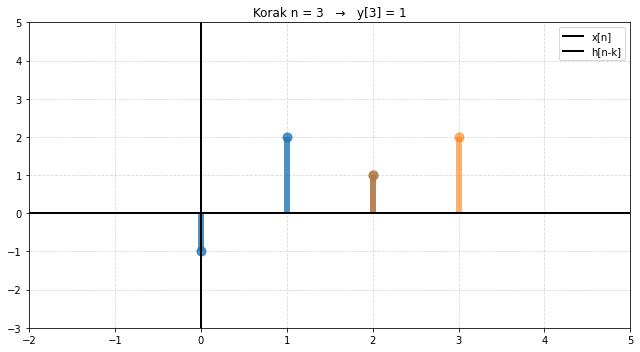


Konačni signali:


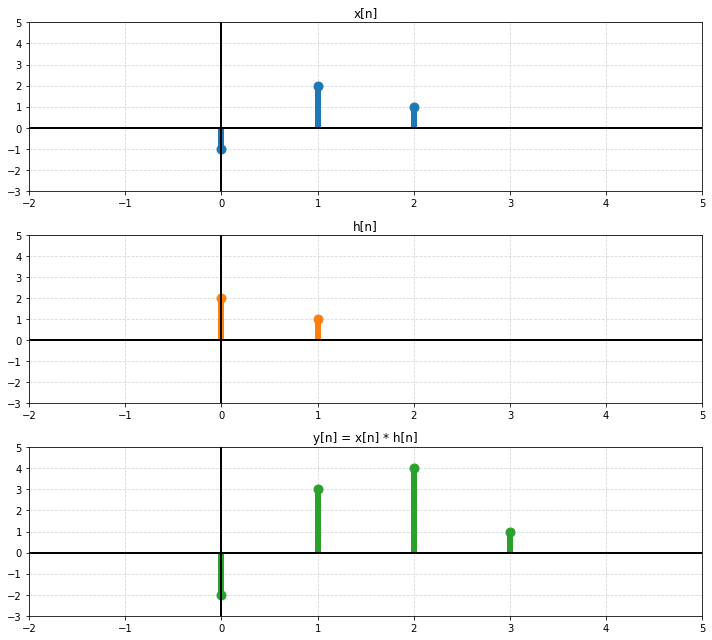

In [10]:
## Vizualno po koracima

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve


def plot_steps(x, h):

    y = np.convolve(x, h)

    # flip h -> h[-k]
    h_flip = h[::-1]

    x_index = np.arange(len(x))
    h_index = np.arange(-(len(h)-1),1)

    # globalni raspon osi
    xmin = -2
    xmax = len(x)+2
    ymin = -3
    ymax = 5

    for n in range(len(y)):

        shift = n
        h_shift_index = h_index + shift

        plt.figure(figsize=(9,5))

        # x[n]
        markerline, stemlines, _ = plt.stem(x_index, x, basefmt=" ")
        plt.setp(stemlines, linewidth=6, color="tab:blue", alpha=0.8)
        plt.setp(markerline, markersize=9, color="tab:blue", alpha=0.8)

        # h[n-k]
        markerline2, stemlines2, _ = plt.stem(h_shift_index, h_flip, basefmt=" ")
        plt.setp(stemlines2, linewidth=6, color="tab:orange", alpha=0.6)
        plt.setp(markerline2, markersize=9, color="tab:orange", alpha=0.6)

        # osi
        plt.axhline(0, color='black', linewidth=2)
        plt.axvline(0, color='black', linewidth=2)

        plt.grid(True, linestyle="--", alpha=0.5)

        plt.title(f"Korak n = {n}   →   y[{n}] = {y[n]}")
        plt.xlim(xmin, xmax)
        plt.ylim(ymin, ymax)

        plt.legend(["x[n]", "h[n-k]"])

        plt.tight_layout()
        plt.show()


def plot_result(x, h, y):

    x_index = np.arange(len(x))
    h_index = np.arange(len(h))
    y_index = np.arange(len(y))

    xmin = -2
    xmax = len(y)+1
    ymin = -3
    ymax = 5

    plt.figure(figsize=(10,9))

    # x[n]
    plt.subplot(3,1,1)
    markerline, stemlines, _ = plt.stem(x_index, x, basefmt=" ")
    plt.setp(stemlines, linewidth=6, color="tab:blue")
    plt.setp(markerline, markersize=9, color="tab:blue")
    plt.axhline(0,color='black',linewidth=2)
    plt.axvline(0,color='black',linewidth=2)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xlim(xmin, xmax)
    plt.ylim(ymin, ymax)
    plt.title("x[n]")

    # h[n]
    plt.subplot(3,1,2)
    markerline, stemlines, _ = plt.stem(h_index, h, basefmt=" ")
    plt.setp(stemlines, linewidth=6, color="tab:orange")
    plt.setp(markerline, markersize=9, color="tab:orange")
    plt.axhline(0,color='black',linewidth=2)
    plt.axvline(0,color='black',linewidth=2)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xlim(xmin, xmax)
    plt.ylim(ymin, ymax)
    plt.title("h[n]")

    # y[n]
    plt.subplot(3,1,3)
    markerline, stemlines, _ = plt.stem(y_index, y, basefmt=" ")
    plt.setp(stemlines, linewidth=6, color="tab:green")
    plt.setp(markerline, markersize=9, color="tab:green")
    plt.axhline(0,color='black',linewidth=2)
    plt.axvline(0,color='black',linewidth=2)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xlim(xmin, xmax)
    plt.ylim(ymin, ymax)
    plt.title("y[n] = x[n] * h[n]")

    plt.tight_layout()
    plt.show()


def main():

    x = np.array([-1,2,1])
    h = np.array([2,1])

    y_numpy = np.convolve(x,h)
    y_scipy = convolve(x,h)

    print("NumPy rezultat :", y_numpy)
    print("SciPy rezultat :", y_scipy)

    print("\nKoraci konvolucije:")
    plot_steps(x,h)

    print("\nKonačni signali:")
    plot_result(x,h,y_numpy)


if __name__ == "__main__":
    main()

## NumPy vs SciPy.signal konvolucija

U implementaciji konvolucije najčešće se koriste funkcije iz biblioteka __NumPy__ i __SciPy.signal__. Funkcija `numpy.convolve` podržava samo jednodimenzionalne nizove pa se uglavnom koristi za jednostavne zadatke u obradi 1D signala. `scipy.signal` nudi širi skup funkcija koje podržavaju konvoluciju višedimenzionalnih nizova zbog čega se koristi u obradi slike, filtriranju i općenito u primjenama koje uključuju višedimenzionalne podatke. Obje implementacije nude odabir načina rada konvolucije (modovi konvolucije; opisano u nastavku), ali se kod SciPy-ja dodatno može odabrati i metoda računanja: direktnim postupkom u vremenskoj domeni ili korištenjem Fourierove transformacije. Za dulje signale učinkovitiji je pristup Fourierovom transformacijom jer pretvara konvoluciju u množenje u frekvencijskoj domeni (o tome ćemo kasnije), što značajno smanjuje broj potrebnih operacija.

Službene opise tih dviju funkcija možete pročitati pomoću python naredbi help(np.convolve) i help(scipy.signal.convolve).


In [ ]:
# help(np.convolve)
# help(scipy.signal.convolve) 

## Načini rada konvolucije

U opisima funkcija navedena su tri načina rada konvolucije koji se razlikuju u dimenziji izlaza $y[n]$.

Ako s $N$ označimo broj uzoraka signala $x[n]$, a s $K$ broj uzoraka signala $h[n]$, dimenzija izlaza će ovisiti o odabranom načinu rada:


### Full
- **Dimenzija izlaza:** $N+K-1$
- Zadržava sve informacije iz oba signala (*warm-up* i *ringing-out* faze)
- Koristi se u analizi signala, preciznim obradama i vizualizaciji

### Valid
- **Dimenzija izlaza:** $N-K+1$
- Zadržava samo rezultate konvolucije kada se signali u potpunosti preklapaju (bez *warm-up* i *ringing-out* faza)
- Eliminira rubne efekte koji unose šum
- Koristi se kod detekcije uzoraka

### Same
- **Dimenzija izlaza:** $N$
- Izlazna dimenzija jednaka je dimenziji ulaznog signala $x[n]$
- Koristi se u obradi slike i u konvolucijskim neuronskim mrežama (CNN)
- dodaje $K-1$ nula na ulazni signal kako se dimenzija izlaza ne bi mijenjala



NumPy i SciPy.signal omogućuju sva tri načina rada, a zadani (*default*) je `'full'`.

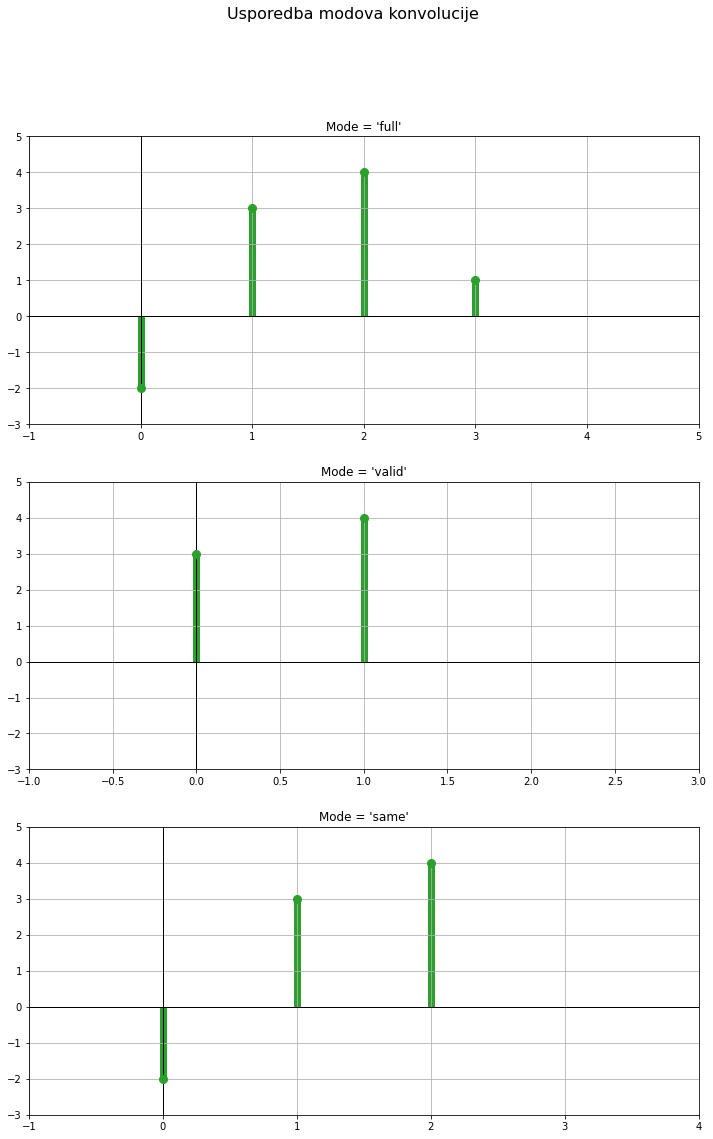


RAZLIKE IZMEĐU MODOVA KONVOLUCIJE:

1. 'full'  - koristi cijeli preklop signala, rezultat duljine N+K-1
2. 'valid' - vraća samo dijelove gdje se h[n] potpuno preklapa s x[n]
3. 'same'  - vraća rezultat iste duljine kao x[n]


In [9]:
modes = ['full', 'valid', 'same']


x = {0: -1, 1: 2, 2: 1}
h = {0: 2, 1: 1}

x_arr = [x.get(n, 0) for n in range(min(x), max(x)+1)]
h_arr = [h.get(n, 0) for n in range(min(h), max(h)+1)]



fig, axs = plt.subplots(3, 1, figsize=(12, 18))
fig.suptitle("Usporedba modova konvolucije", fontsize=16)
for i, mode in enumerate(modes):
    result = scipy_convolve(x_arr, h_arr, mode=mode)
    markerline3, stemlines3, baseline3 = axs[i].stem(result, basefmt=" ", use_line_collection=True)
    plt.setp(stemlines3, linewidth=7, zorder=1, color='tab:green')
    plt.setp(markerline3, markersize=8, zorder=31, color='tab:green')
    axs[i].set_title(f"Mode = '{mode}'")
    axs[i].grid(True)
    axs[i].axhline(0, color='black', linewidth=1)
    axs[i].axvline(0, color='black', linewidth=1)
    axs[i].set_xlim(-1, len(result) + 1)
    axs[i].set_ylim(-3, 5)

plt.show()

# Objašnjenje razlika
print("\nRAZLIKE IZMEĐU MODOVA KONVOLUCIJE:\n")
print("1. 'full'  - koristi cijeli preklop signala, rezultat duljine N+K-1")
print("2. 'valid' - vraća samo dijelove gdje se h[n] potpuno preklapa s x[n]")
print("3. 'same'  - vraća rezultat iste duljine kao x[n]")

***

## Korelacija diskretnih signala

__Korelacija__ mjeri sličnost između dva signala. U operaciji korelacije jedan se signal (također zvan jezgra, engleski _kernel_, označen kao $h[n]$) pomiče duž drugog, ulaznog signala $x[n]$, i u svakom se pomaku računa suma umnožaka odgovarajućih uzoraka. Rezultat je novi signal koji prikazuje koliko su i u kojim trenucima dva signala slična. 

Diskretna korelacija dvaju signala $x[n]$ i $h[n]$ definirana je kao:

$$
r_{xh}[n]=\sum_{k=-\infty}^{\infty} x[k]h[n+k]
$$

Slično kao i kod konvolucije, kernel „prelazi“ preko ulaznog signala, no ključna razlika je u tome da se kernel ne zrcali. Upravo zbog toga se za konvoluciju kaže da filtrira signal (stvara novi transformirani signal), dok korelacija daje mjeru sličnosti između dva signala kroz različite pomake.

Često se kao poveznica između konvolucije i korelacije piše:

$$
r_{xh}[n]=x[n]*h[-n]
$$

jer je korelacija zapravo konvolucija s vremenski zrcaljenim filtrom.

***

Korelaciju dijelimo na:
 - __križna korelacija__ - signali između kojih se mjeri sličnost su različiti
   - primjenjuje se u detekciji poznatog uzorka
 - __autokorelacija__ - korelacija signala sa samim sobom
   - primjenjuje se u otkrivanju ponavljajućih uzoraka i skrivenih periodičnosti

Kao i konvolucija, korelacija može biti izvedena u trima režimima:
 - 'full' – vraća cijeli rezultat (uključuje sve preklapanja),
 - 'valid' – samo one pozicije gdje se kernel potpuno preklapa sa signalom,
 - 'same' – rezultat je iste veličine kao ulazni signal.


U implementaciji se najčešće koriste funkcije:
 - __numpy.correlate()__ – za 1D signale,
 - __scipy.signal.correlate()__ – podržava i višedimenzionalne podatke (npr. slike).



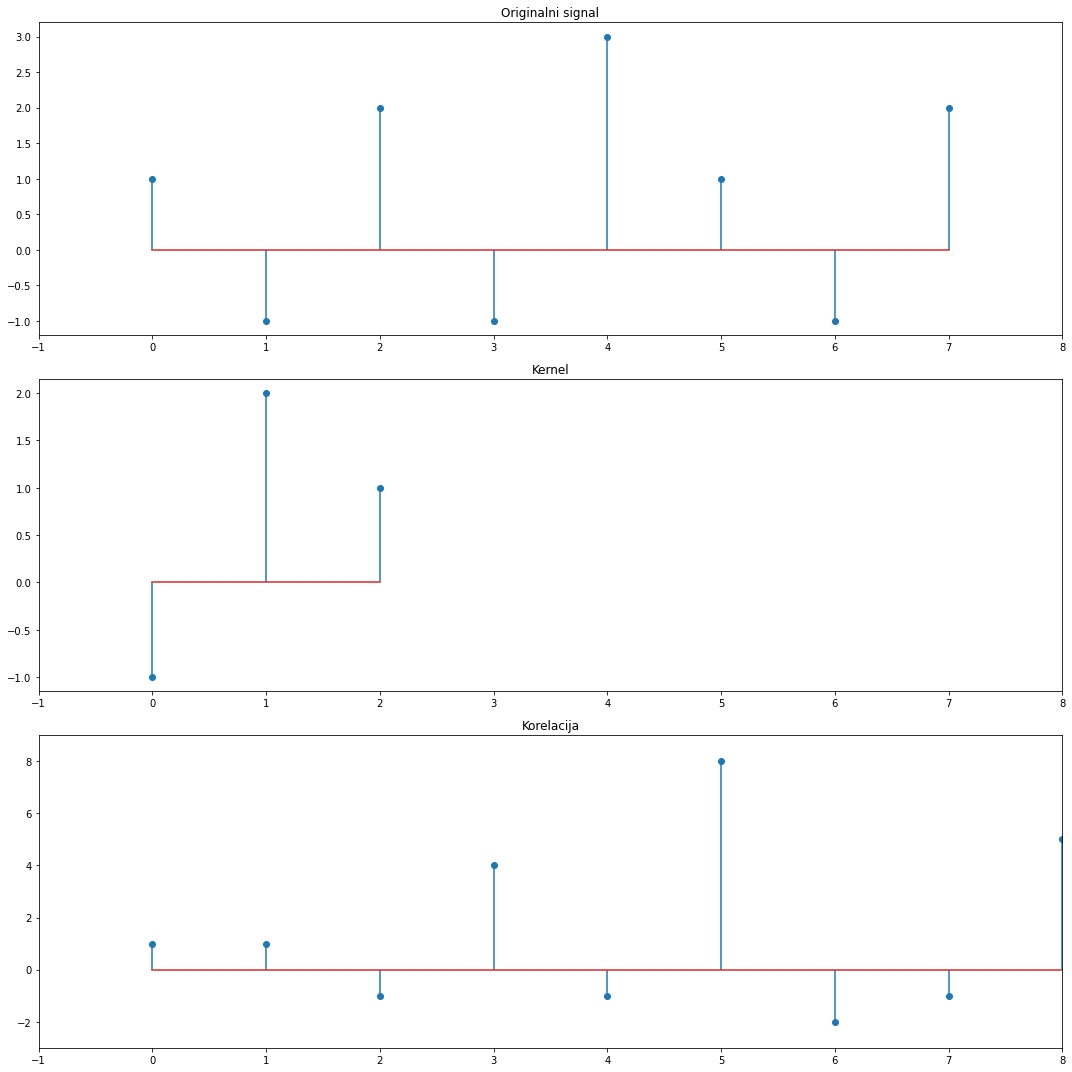

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, convolve

# Originalni signal: niz sa skrivenim "uzorkom"
signal = np.array([1, -1, 2, -1, 3, 1, -1, 2])

# Uzorak (kernel) koji tražimo u signalu
kernel = np.array([-1, 2, 1])

# Korelacija: traži gdje je signal sličan uzorku
corr = correlate(signal, kernel, mode='full')

# Priprema figure
plt.figure(figsize=(15, 15))

# Iste osi
x_max = len(signal)
y_min = min(signal.min(), corr.min(), corr.min()) - 1
y_max = max(signal.max(), corr.max(), corr.max()) + 1

# 1. Originalni signal
plt.subplot(3, 1, 1)
plt.stem(np.arange(len(signal)), signal, use_line_collection=True)
plt.title("Originalni signal")
plt.xlim(-1, x_max)

plt.subplot(3, 1, 2)
plt.stem(np.arange(len(kernel)), kernel, use_line_collection=True)
plt.title("Kernel")
plt.xlim(-1, x_max)

# 2. Korelacija
plt.subplot(3, 1, 3)
plt.stem(np.arange(len(corr)), corr, use_line_collection=True)
plt.title("Korelacija")
plt.xlim(-1, x_max)
plt.ylim(y_min, y_max)


plt.tight_layout()
plt.show()



***
## Prilagođeni filtar

U radarskim sustavima odašiljač generira i emitira impuls koji se reflektira od nekog objekta u okruženju (npr. aviona). U pravilu radari koriste vrijeme kašnjenja reflektiranog impulsa u odnosu na poslani kako bi odredili udaljenost do promatranog objekta. Problem je što primljeni signal često bude pun šuma pa je teško odrediti točan trenutak u kojem se impuls vratio. Ipak, budući da radarski sustav zna kako taj poslani impuls izgleda, može se koristiti korelacija za njegovu preciznu detekciju.

Upravo to radi __prilagođeni filtar (_Matched Filter_)__. Prilagođeni filtar korelira cijeli primljeni signal s poznatim impulsom koji je radar poslao. Kažemo da prilagođeni filtar povećava odnos signala i šuma (eng. _Signal to Noise Ratio_, SNR). Na taj način moguće je istaknuti impuls čak i kad je jako zagađen šumom. Trenutak u kojem se postiže najveća korelacija uzima se kao vrijeme dolaska reflektiranog impulsa, što se kasnije koristi za mjerenje udaljenosti.

U nastavku je generiran signal čija se frekvencija linearno mijenja u vremenu, tzv. signal _chirp_. Chirp se i inače često koristi u radarskim sustavima upravo zbog jednostavnije detekcije, ali i zato što porast frekvencije omogućuje preciznije određivanje udaljenosti. Nakon što emitirani chirp prođe kroz kanal, vraća se zakasnio u vremenu i sa šumom. Na trećoj se slici vidi rezultat korelacije primljenog (šumovitog) signala i generiranog chirpa koja ističe dio gdje se nalazi sličan uzorak.

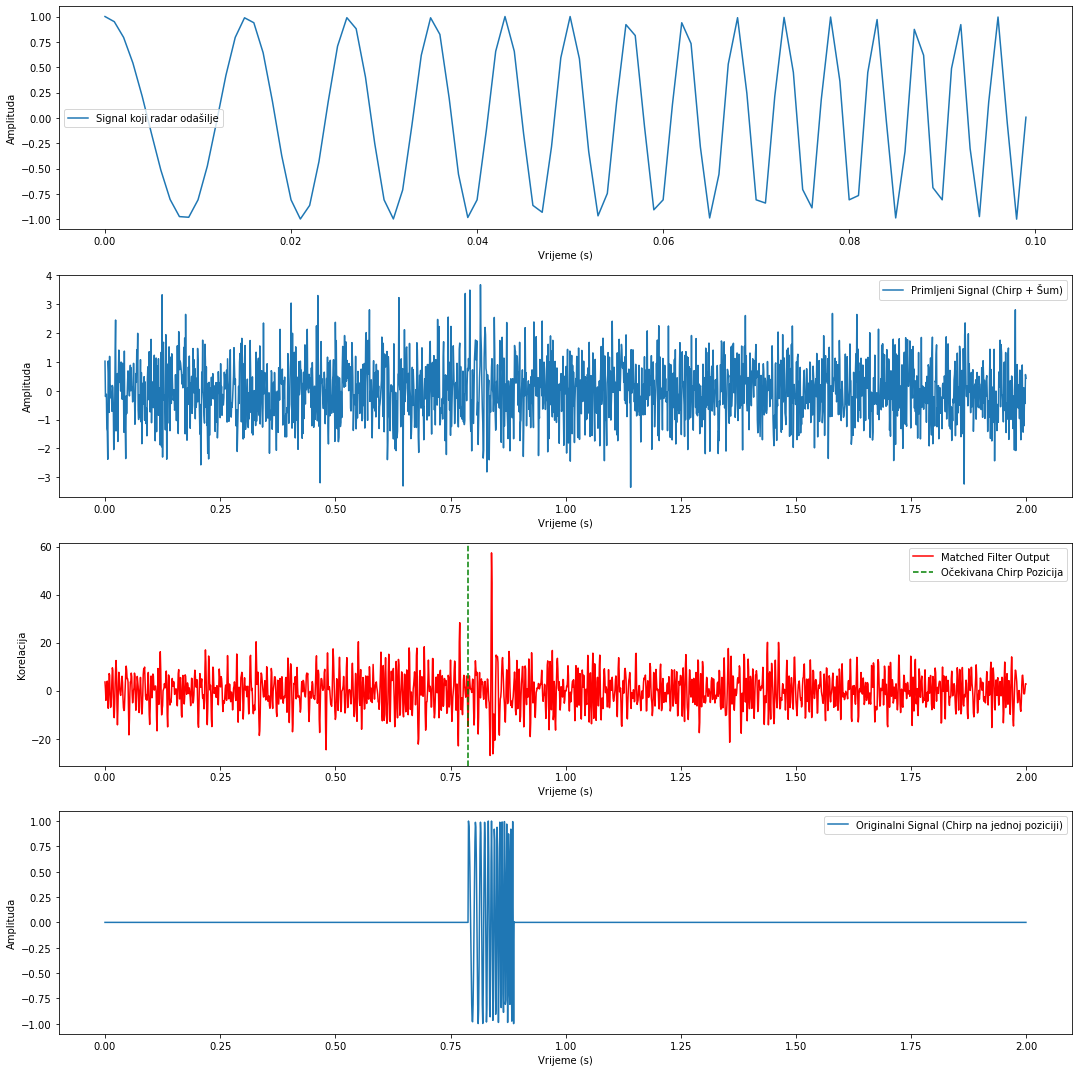

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp, correlate

fs = 1000    
T = 2.0      
t = np.linspace(0, T, int(fs * T), endpoint=False)  # Vremenska os

# Parametri chirp signala
f0 = 50   # Početna frekvencija (Hz)
f1 = 250  # Krajnja frekvencija (Hz)
chirp_duration = 0.1  

chirp_start = np.random.randint(0, len(t) - int(chirp_duration * fs))

signal = np.zeros_like(t)  
chirp_t = np.linspace(0, chirp_duration, int(fs * chirp_duration), endpoint=False)
chirp_signal = chirp(chirp_t, f0=f0, f1=f1, t1=chirp_duration, method='linear')

# Ubacujemo chirp u signal
signal[chirp_start:chirp_start + len(chirp_signal)] = chirp_signal

# Dodavanje Gaussovog šuma
noise = np.random.normal(0, 1, len(t))
received_signal = signal + noise  # Simulacija primljenog signala

matched_filter = chirp_signal  

correlation_output = correlate(received_signal, matched_filter, mode='same')

plt.figure(figsize=(15, 15))

plt.subplot(4, 1, 1)
plt.plot(chirp_t, chirp_signal, label="Signal koji radar odašilje")
plt.legend()
plt.xlabel("Vrijeme (s)")
plt.ylabel("Amplituda")

plt.subplot(4, 1, 2)
plt.plot(t, received_signal, label="Primljeni Signal (Chirp + Šum)")
plt.legend()
plt.xlabel("Vrijeme (s)")
plt.ylabel("Amplituda")

plt.subplot(4, 1, 3)
plt.plot(t, correlation_output, color='r', label="Matched Filter Output")
plt.axvline(t[chirp_start], color='g', linestyle='--', label="Očekivana Chirp Pozicija")
plt.legend()
plt.xlabel("Vrijeme (s)")
plt.ylabel("Korelacija")

plt.subplot(4, 1, 4)
plt.plot(t, signal, label="Originalni Signal (Chirp na jednoj poziciji)")
plt.legend()
plt.xlabel("Vrijeme (s)")
plt.ylabel("Amplituda")

plt.tight_layout()
plt.show()

## Autokorelacija

Ako imamo niz otkucaja srca (EKG), __autokorelacija__ može otkriti pravilne razmake između otkucaja. Periodičnost u autokorelaciji označava konzistentan srčani ritam, dok nepravilnosti mogu ukazivati na aritmije.

U nastavku je generiran signal koji simulira EKG snimku. Autokorelacija ističe pravilnu periodičnost tog signala.

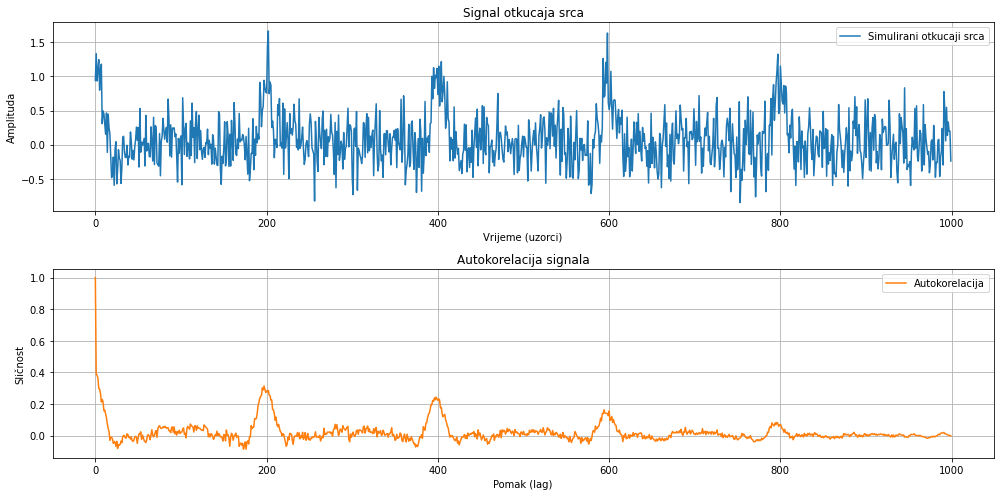

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, find_peaks

# Simulirani signal otkucaja srca
n = np.arange(0, 1000)
heartbeat = np.zeros_like(n)
heartbeat[::200] = 1  # otkucaji srca svakih 200 uzoraka

# Dodavanje šuma
heartbeat_signal = np.convolve(heartbeat, np.hamming(30), mode='same') + 0.3 * np.random.randn(len(n))

autocorr = correlate(heartbeat_signal, heartbeat_signal, mode='full')
lags = np.arange(-len(heartbeat_signal) + 1, len(heartbeat_signal))

# Normalizacija
autocorr = autocorr / np.max(autocorr)

# Detekcija vrhova u autokorelaciji za pozitivne pomake
center = len(autocorr) // 2
autocorr_positive = autocorr[center:]
lags_positive = lags[center:]

peaks, _ = find_peaks(autocorr_positive, height=0.5, distance=50)
detected_period = lags_positive[peaks[1]] if len(peaks) > 1 else None

# Prikaz
plt.figure(figsize=(14, 7))

plt.subplot(2, 1, 1)
plt.plot(n, heartbeat_signal, label='Simulirani otkucaji srca', color='tab:blue')
plt.title("Signal otkucaja srca")
plt.xlabel("Vrijeme (uzorci)")
plt.ylabel("Amplituda")
plt.grid(True)
plt.legend()


plt.subplot(2, 1, 2)
plt.plot(lags_positive, autocorr_positive, color='tab:orange', label='Autokorelacija')
plt.title("Autokorelacija signala")
plt.xlabel("Pomak (lag)")
plt.ylabel("Sličnost")
plt.grid(True)
plt.legend()

if detected_period:
    plt.suptitle(f"Otkriveni dominantni period: {detected_period} uzoraka", fontsize=14, color='green')

plt.tight_layout()
plt.show()

***

## Konvolucija i korelacija u slikama (2D)


Kad govorimo o konvoluciji i korelaciji na slikama, mislimo na primjenu istih operacija koje smo vidjeli na 1D signalima, ali sada nad **dvodimenzionalnim matricama**.

Označimo ulaznu sliku s $I[x,y]$, a kernel (filtar) s $K[m,n]$, gdje su $x, y$ indeksi piksela slike, a $m, n$ indeksi vrijednosti unutar kernela. Konvoluciju i korelaciju tada računamo ovako:

### Konvolucija

$$O[x,y] = \sum_{m} \sum_{n} I[x-m,\ y-n] \cdot K[m,n]$$

Kernel se **zrcali** u oba smjera prije nego što počne prelaziti po slici.

### Korelacija

$$O[x,y] = \sum_{m} \sum_{n} I[x+m,\ y+n] \cdot K[m,n]$$

Kernel se pomiče po slici **bez zrcaljenja** ($x+m$, $y+n$). Na svakoj poziciji mjeri se sličnost između kernela i odgovarajućeg dijela slike.


Jedina matematička razlika je predznak indeksa: $x-m$ kod konvolucije nasuprot $x+m$ kod korelacije. Za **simetrične kernele** (npr. Gaussov blur) zrcaljenje ne mijenja ništa, pa su rezultati identični. 

 ***
__Gaussov blur filtar__<br>
Gaussova funkcija se često koristi za zamućenje slika. Funkcija ima najveću vrijednost u sredini i simetrično opada prema rubovima. Kod konvolucije sa Gaussovom funkcijom, dolazi do uklanjanja visokofrekvencijskih komponenti slike, odnosno slika postaje glađa, a detalji se brišu (blur efekt).
Gaussov filtar se koristi za izračun nove vrijednosti svakog piksela tako da centralni piksel ima najveću težinu, a susjedni pikseli doprinose novoj vrijednosti piksela, ali s manjom težinom što su udaljeniji od središta.

U slučaju Gaussovog filtra veličine 3x3 njegovi će elementi iznositi: 

| 1 | 2 | 1 |<br>
| 2 | 4 | 2 |$\cdot \frac{1}{16}$<br>
| 1 | 2 | 1 |

To znači da će pikseli slike koji se u tom trenutku preklapaju s tim filtrom biti pomnoženi s tim elementima i zbrojeni kako bi se izračunala nova vrijednost piksela koji se nalazi na centralnoj poziciji tog dijela slike. Svaki element filtra je podijeljen sa 16 kako bi zbroj bio 1.

S druge strane, __Mean blur filtar__ postavlja vrijednost centralnog piksela u prosječnu vrijednost svih piksela u okolici. Elementi tog filtra u osnovnoj veličini (3x3) glase:

| 1 | 1 | 1 |<br>
| 1 | 1 | 1 | $\cdot \frac{1}{9}$<br>
| 1 | 1 | 1 |



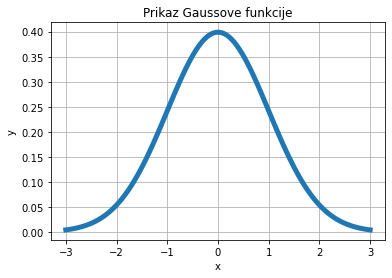

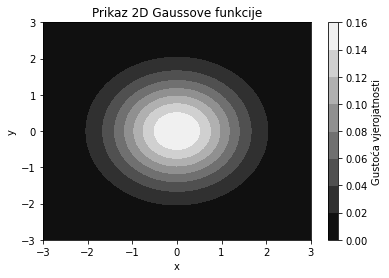

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve


# Definiranje Gaussove funkcije
def gaussian(x, mu, sig):
    return (1.0 / (np.sqrt(2.0 * np.pi) * sig) * np.exp(-np.power((x - mu) / sig, 2.0) / 2)
    )

# Definiranje 2D Gaussove funkcije
def gaussian_2d(x, y, mu_x, mu_y, sig_x, sig_y):
    return (1.0 / (2.0 * np.pi * sig_x * sig_y) * 
            np.exp(-((x - mu_x)**2 / (2 * sig_x**2) + (y - mu_y)**2 / (2 * sig_y**2))))

# Parametri potrebni za Gaussovu funkciju
mu = 0
sig = 1
x = np.linspace(-3*sig, 3*sig, 120)


# Iscrtavanje Gaussove funkcije
plt.figure()
plt.plot(x, gaussian(x, mu, sig), linewidth=5)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Prikaz Gaussove funkcije')
plt.grid()
plt.show()


# Parametri potrebni za 2D Gaussovu funkciju
mu_x = 0
mu_y = 0
sig_x = 1
sig_y = 1
x = np.linspace(-3*sig_x, 3*sig_x, 120)
y = np.linspace(-3*sig_y, 3*sig_y, 120)
x, y = np.meshgrid(x, y)

# Izračunavanje Gaussove funkcije za svaku točku u mreži
z = gaussian_2d(x, y, mu_x, mu_y, sig_x, sig_y)


# Iscrtavanje 2D Gaussove funkcije
plt.figure()
plt.contourf(x, y, z, cmap='gray')
plt.colorbar(label='Gustoća vjerojatnosti')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Prikaz 2D Gaussove funkcije')
plt.show()

U praksi se **blur filtar** često koristi kod obrade skeniranih fotografija. Naime, kada se fizičke fotografije skeniraju i zatim uvećaju, postaju vidljive sitne točkice koje su posljedica načina ispisa i strukture slike.

Zamućivanje slike (engl. blur) služi za omekšavanje prijelaza između svjetlijih i tamnijih dijelova slike. Pritom se svaki piksel zamjenjuje težinskom kombinacijom svoje vrijednosti i vrijednosti susjednih piksela.

Kod **Gaussovog filtra** veći utjecaj imaju pikseli koji su bliže promatranom pikselu, dok udaljeniji pikseli imaju manji utjecaj. Taj se utjecaj kontrolira standardnom devijacijom ($\sigma$), koja određuje širinu Gaussove funkcije. Veća vrijednost $\sigma$ znači da šire susjedstvo piksela značajno utječe na rezultat (jače zamućenje), dok manja vrijednost $\sigma$ ograničava utjecaj na bliže susjede (slabije zamućenje).

Iako funkcija `scipy.ndimage.convolve` nominalno provodi konvoluciju, u ovom slučaju nije bitno radi li se o konvoluciji ili korelaciji. Razlog je simetrija Gaussovog filtra: budući da je jezgra (kernel) simetrična, njezino zrcaljenje, koje razlikuje konvoluciju od korelacije, ne mijenja rezultat.


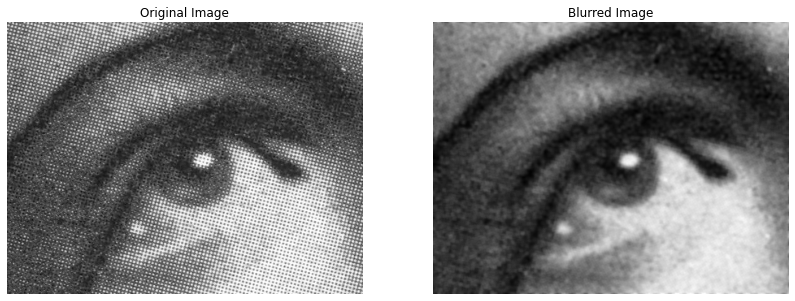

In [9]:
import numpy as np
import scipy.ndimage
import matplotlib.pyplot as plt
from PIL import Image

def gaussian_kernel(size, sigma=1):
    x = np.linspace(-sigma, sigma, size + 1)
    kernel1d = np.diff(scipy.stats.norm.cdf(x))
    kernel2d = np.outer(kernel1d, kernel1d)
    kernel2d /= kernel2d.sum()
    return kernel2d

image_path = 'slike_03/01_Skenirano_oko.JPG'  
image = Image.open(image_path).convert('L')  
image_np = np.array(image)

kernel_size = 5
sigma = 1.0
gaussian_kernel = gaussian_kernel(kernel_size, sigma)

# Primjena Gaussovog filtra
blurred_image = scipy.ndimage.convolve(image_np, gaussian_kernel, mode='reflect')

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image_np, cmap='gray')
plt.axis('off')  # Hide axes for a cleaner look

plt.subplot(1, 2, 2)
plt.title('Blurred Image')
plt.imshow(blurred_image, cmap='gray')
plt.axis('off')

plt.show()

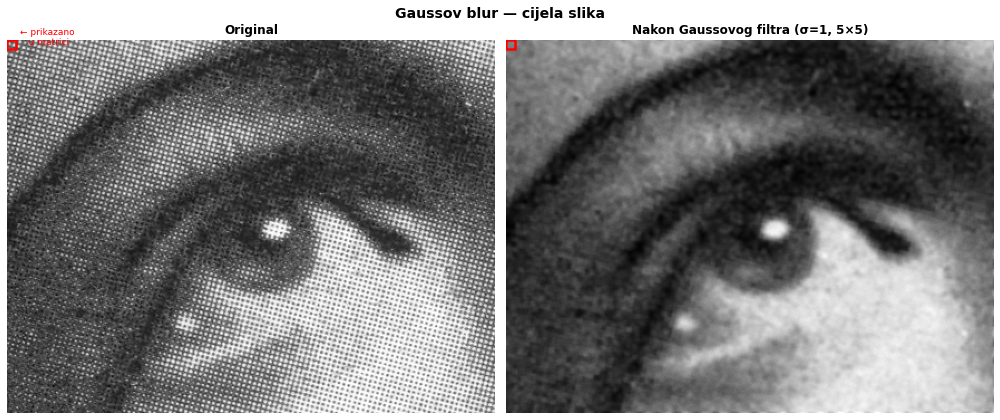

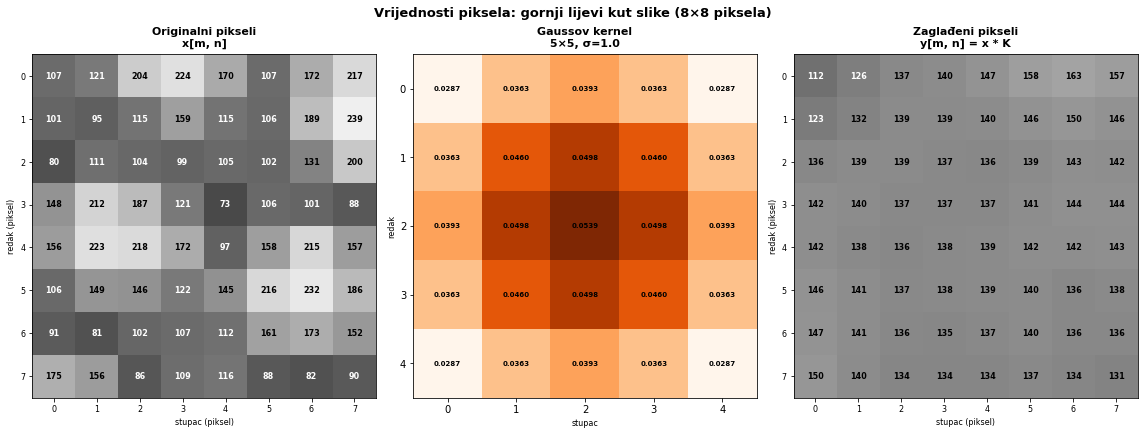

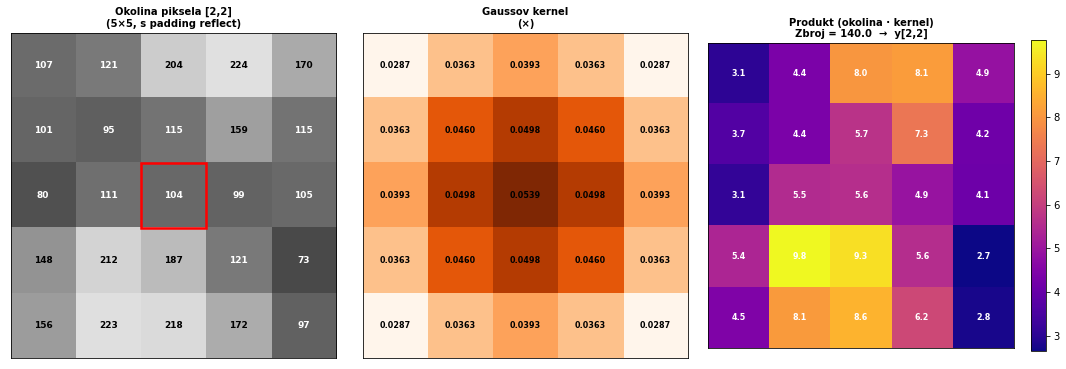

In [10]:
## Isti primjer, ali s detaljnijim prikazom promjene vrijednosti jednog piksela Gaussovim filtrom

import numpy as np
import scipy.ndimage
import scipy.stats
import matplotlib.pyplot as plt
from PIL import Image


def gaussian_kernel(size, sigma=1):
    x = np.linspace(-sigma, sigma, size + 1)
    kernel1d = np.diff(scipy.stats.norm.cdf(x))
    kernel2d = np.outer(kernel1d, kernel1d)
    kernel2d /= kernel2d.sum()
    return kernel2d


image_path = 'slike_03/01_Skenirano_oko.JPG'
image = Image.open(image_path).convert('L')
image_np = np.array(image)

kernel_size = 5
sigma = 1.0
gauss_kernel = gaussian_kernel(kernel_size, sigma)

blurred_image = scipy.ndimage.convolve(image_np, gauss_kernel, mode='reflect')


def plot_matrix(ax, data, title, cmap='gray', vmin=0, vmax=255,
                fontsize=9, fmt=None):
    """Prikaže 2D matricu kao heatmap s vrijednostima u svakoj ćeliji."""
    ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax, aspect='equal',
              interpolation='nearest')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    rows, cols = data.shape
    for i in range(rows):
        for j in range(cols):
            val = data[i, j]
            if fmt == 'float4':
                txt = f"{val:.4f}"
            elif fmt == 'float2':
                txt = f"{val:.2f}"
            else:
                txt = str(int(round(val)))
            # bijeli tekst na tamnim pikselima, crni na svjetlima
            brightness = val / vmax if vmax != 0 else 0
            color = 'white' if brightness < 0.5 else 'black'
            ax.text(j, i, txt, ha='center', va='center',
                    fontsize=fontsize, color=color, fontweight='bold')
    ax.set_xticks(np.arange(cols))
    ax.set_yticks(np.arange(rows))
    ax.set_xticklabels(np.arange(cols), fontsize=8)
    ax.set_yticklabels(np.arange(rows), fontsize=8)
    ax.set_xlabel("stupac (piksel)", fontsize=8)
    ax.set_ylabel("redak (piksel)", fontsize=8)

# ODABERI REGIJU — gornji lijevi kut
PATCH_ROW, PATCH_COL = 0, 0   # gornji lijevi kut
PATCH_SIZE = 8                  # prikazujemo 8x8 piksela

patch_orig   = image_np[PATCH_ROW:PATCH_ROW+PATCH_SIZE,
                         PATCH_COL:PATCH_COL+PATCH_SIZE]
patch_blur   = blurred_image[PATCH_ROW:PATCH_ROW+PATCH_SIZE,
                              PATCH_COL:PATCH_COL+PATCH_SIZE]


fig1, axs1 = plt.subplots(1, 2, figsize=(14, 6))
fig1.suptitle("Gaussov blur — cijela slika", fontsize=14, fontweight='bold')

axs1[0].imshow(image_np, cmap='gray')
axs1[0].set_title("Original", fontsize=12, fontweight='bold')
axs1[0].axis('off')

rect = plt.Rectangle((PATCH_COL - 0.5, PATCH_ROW - 0.5),
                       PATCH_SIZE, PATCH_SIZE,
                       edgecolor='red', facecolor='none', linewidth=2.5)
axs1[0].add_patch(rect)
axs1[0].text(PATCH_COL + PATCH_SIZE + 3, PATCH_ROW + PATCH_SIZE // 2,
             "← prikazano\n   u matrici", color='red', fontsize=9)

axs1[1].imshow(blurred_image, cmap='gray')
axs1[1].set_title("Nakon Gaussovog filtra (σ=1, 5×5)", fontsize=12, fontweight='bold')
axs1[1].axis('off')
rect2 = plt.Rectangle((PATCH_COL - 0.5, PATCH_ROW - 0.5),
                        PATCH_SIZE, PATCH_SIZE,
                        edgecolor='red', facecolor='none', linewidth=2.5)
axs1[1].add_patch(rect2)

plt.tight_layout()
plt.show()


fig2, axs2 = plt.subplots(1, 3, figsize=(16, 6))
fig2.suptitle(
    f"Vrijednosti piksela: gornji lijevi kut slike ({PATCH_SIZE}×{PATCH_SIZE} piksela)",
    fontsize=13, fontweight='bold'
)

plot_matrix(axs2[0], patch_orig, "Originalni pikseli\nx[m, n]",
            fontsize=8)

plot_matrix(axs2[1], gauss_kernel * 1000,
            f"Gaussov kernel (×1000)\n{kernel_size}×{kernel_size}, σ={sigma}",
            cmap='Oranges', vmin=0, vmax=(gauss_kernel * 1000).max(),
            fontsize=7, fmt='float2')

axs2[1].cla()
axs2[1].imshow(gauss_kernel, cmap='Oranges', aspect='equal',
               interpolation='nearest')
axs2[1].set_title(f"Gaussov kernel\n{kernel_size}×{kernel_size}, σ={sigma}",
                  fontsize=11, fontweight='bold', pad=8)
for i in range(kernel_size):
    for j in range(kernel_size):
        axs2[1].text(j, i, f"{gauss_kernel[i,j]:.4f}",
                     ha='center', va='center', fontsize=7,
                     color='black', fontweight='bold')
axs2[1].set_xticks(np.arange(kernel_size))
axs2[1].set_yticks(np.arange(kernel_size))
axs2[1].set_xlabel("stupac", fontsize=8)
axs2[1].set_ylabel("redak", fontsize=8)

plot_matrix(axs2[2], patch_blur, "Zaglađeni pikseli\ny[m, n] = x * K",
            fontsize=8)

plt.tight_layout()
plt.show()


TARGET_R, TARGET_C = 2, 2   # piksel čiji izračun prikazujemo
pad = kernel_size // 2       # = 2 za kernel 5x5

padded = np.pad(image_np, pad, mode='reflect')
okolina = padded[TARGET_R: TARGET_R + kernel_size,
                 TARGET_C: TARGET_C + kernel_size].astype(float)

produkt = okolina * gauss_kernel
y_val   = produkt.sum()

fig3, axs3 = plt.subplots(1, 3, figsize=(15, 5))


axs3[0].imshow(okolina, cmap='gray', vmin=0, vmax=255, aspect='equal',
               interpolation='nearest')
axs3[0].set_title(f"Okolina piksela [{TARGET_R},{TARGET_C}]\n(5×5, s padding reflect)",
                  fontsize=10, fontweight='bold')
for i in range(kernel_size):
    for j in range(kernel_size):
        brightness = okolina[i, j] / 255
        color = 'white' if brightness < 0.5 else 'black'
        axs3[0].text(j, i, str(int(okolina[i, j])),
                     ha='center', va='center', fontsize=9,
                     color=color, fontweight='bold')
axs3[0].add_patch(plt.Rectangle((pad-0.5, pad-0.5), 1, 1,
                                  edgecolor='red', facecolor='none', lw=2.5))
axs3[0].set_xticks([]); axs3[0].set_yticks([])

# kernel
axs3[1].imshow(gauss_kernel, cmap='Oranges', aspect='equal',
               interpolation='nearest')
axs3[1].set_title("Gaussov kernel\n(×)", fontsize=10, fontweight='bold')
for i in range(kernel_size):
    for j in range(kernel_size):
        axs3[1].text(j, i, f"{gauss_kernel[i,j]:.4f}",
                     ha='center', va='center', fontsize=8,
                     color='black', fontweight='bold')
axs3[1].set_xticks([]); axs3[1].set_yticks([])

im3 = axs3[2].imshow(produkt, cmap='plasma', aspect='equal',
                      interpolation='nearest')
axs3[2].set_title(f"Produkt (okolina · kernel)\nZbroj = {y_val:.1f}  →  y[{TARGET_R},{TARGET_C}]",
                   fontsize=10, fontweight='bold')
for i in range(kernel_size):
    for j in range(kernel_size):
        axs3[2].text(j, i, f"{produkt[i,j]:.1f}",
                     ha='center', va='center', fontsize=8,
                     color='white', fontweight='bold')
axs3[2].set_xticks([]); axs3[2].set_yticks([])
plt.colorbar(im3, ax=axs3[2], fraction=0.046)

plt.tight_layout()
plt.show()



***

## 2D korelacija

Za korelaciju smo ranije rekli da se koristi u prepoznavanju uzoraka ili detekciji objekata. Na primjeru u nastavku primijenjena je **2D korelacija** na logo FER-a.

Kao uzorak koji tražimo (*kernel*) kreirana je horizontalna linija dimenzija $3 \times 40$ piksela ispunjena bijelom bojom (vrijednost 255). Funkcija `correlate2d` zatim taj kernel "klizi" po cijeloj slici i na svakoj poziciji računa mjeru sličnosti između kernela i odgovarajućeg dijela slike.

Na mapi korelacije svjetlije boje označavaju pozicije gdje je pronađena veća sličnost s traženim uzorkom. Vidljivo je da su upravo horizontalne trake loga istaknute kao mjesta visoke korelacije.

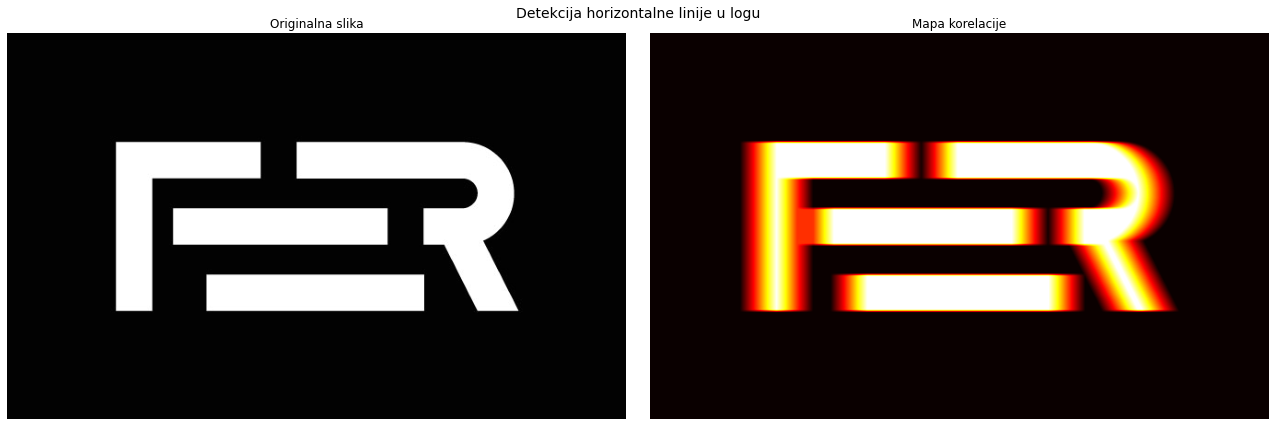

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
from PIL import Image

image_path = "slike_03/FER_logo_2.jpg"
image = Image.open(image_path).convert('L')
image = np.array(image)

kernel = np.ones((3, 40), dtype=np.float32) * 255

correlation = correlate2d(image, kernel, mode='same', boundary='symm')

y, x = np.unravel_index(np.argmax(correlation), correlation.shape)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Originalna slika")
axes[0].axis('off')

axes[1].imshow(correlation, cmap='hot')
axes[1].set_title("Mapa korelacije")
axes[1].axis('off')



plt.suptitle("Detekcija horizontalne linije u logu", fontsize=14)
plt.tight_layout()
plt.show()

***
## Svojstva konvolucije

Neka su $x$, $g$ i $h$ diskretni signali. Tada za konvoluciju vrijedi:

 - komutativnost
  - $x*h = h*x$
 - asocijativnost
  - $(g*h)*x = g*(h*x)$
 - distributivnost
  - $h*x_1+h*x_2 = h*(x_1+x_2)$
  
*dokazi za svojstva su dani niže.
  
  
__Asocijativnost__ se može iskoristiti u slučaju filtriranja nekog dužeg ulaznog signala s kraćim filtrima. Budući da je isto koja dva signala prvo konvoluiramo, izračun konvolucije će vremenski kraće trajati ako prvo konvoluiramo kraće filtre (manje duljine), a na kraju tek njihov izlaz s dužim ulaznim signalom. Taj je primjer prikazan u programskom kodu ispod. Generirana su tri diskretna signala s nasumičnim vrijednostima:<br>
 - $x[n]$ je ulazni i sastoji se od 10.000.000 uzoraka
 - $h_1[n]$ je prvi filtar i sastoji se od 20 uzoraka
 - $h_2[n]$ je drugi filtar i sastoji se od 15 uzoraka
 
Vremena potrebna za izvođenje konvolucija pokazuju da je bolje prvo konvoluirati $h_1$ i $h_2$ pa onda njihov izlaz s $x$.

Slično se može pokazati i za __distributivnost__. Na lijevoj strani izraza imamo dvije konvolucije, a na desnoj jednu pa je opet brži onaj pristup s manje izračuna. 

***

Konvolucija posjeduje još dva svojstva: __invarijantnost na pomak__ i __linearnost__. Ta svojstva su nam važna i u kontekstu cijelih komunikacijskih sustava pa ih pišemo općenitije: 

__Invarijantnost na pomak__

Ako na ulaz nekog sustava dovedemo $x[n]$ i dobijemo izlaz $y[n]$, tada kod sustava koji su invarijantni na pomak za ulaz $x[n-n_0]$ očekujemo izlaz $y[n-n_0]$.

Odnosno, invarijantnost na pomak znači da je za takav sustav svejedno hoćemo li prvo pomaknuti (zakasniti) signal pa ga onda provesti kroz sustav ili ćemo ga prvo provesti kroz sustav pa ga onda pomaknuti (zakasniti). 

Na primjeru konvolucije, za sustav $A$ i signale $x$ i $\Delta$ (gdje je $\Delta$ filtar kojim provodimo kašnjenje određen kao $\Delta=[0,0,0,...,0,1]$ s $d$ nula ispred jedinice, a koji u konvoluciji s drugim signalom pomiče taj signal za $d$ uzoraka), vrijedi:  

 - invarijantnost na pomak
  - $A(\Delta*x)=\Delta*A(x)$
  
__Konvolucija je invarijantna na pomak.__ <br>
Dokaz na primjeru sustava $A(x)=h*x$:<br>
 - $A(\Delta*x)=h*(\Delta*x)$ - asocijativnost<br>
 - $A(\Delta*x)=(h*\Delta)*x$ - komutativnost<br>
 - $A(\Delta*x)=(\Delta*h)*x$ - asocijativnost<br>
 - $A(\Delta*x)=\Delta*(h*x)$<br>
 - $A(\Delta*x)=\Delta*A(x)$
 
 
__Linearnost__<br>
Sustav $A$ je linearan ako za bilo koja dva signala $x_1$ i $x_2$ i bilo koji par brojeva $c_1$ i $c_2$ vrijedi: <br>
  - $A(c_1x_1+c_2x_2)=c_1A(x_1)+c_2A(x_2)$
  
U slučaju $x_2=0$ i $c_2=0$:
 - $A(c_1x_1)=c_1A(x_1)$,<br> 
 
odnosno svejedno je skaliramo li signal prije nego ga provedemo kroz sustav ili skaliramo sam izlaz sustava. To svojstvo zovemo _homogenost_. Sustav je homogen ako ulazni signal pomnožen konstantom daje izlazni signal koji je pomnožen istom tom konstantom: $c_1\cdot x[n]= c_1 \cdot y[n]$ (ako je inače $y[n]$ izlaz za ulazni signal $x[n]$).

U posebnom slučaju kad je $c_1=c_2=1$:
 - $A(x_1+x_2)=A(x_1)+A(x_2)$
 
To svojstvo zovemo i _aditivnost_, a u ovom nam slučaju govori da je kod linearnih sustava svejedno zbrajamo li prvo signale pa ih onda dovodimo na ulaz sustava ili ih zasebno dovodimo pa zbrojimo pojedinačne izlaze sustava . 

__Konvolucija je linearna.__

__Napomena__: Sustave koji su i linearni i invarijantni na pomak zvat ćemo __LTI sustavima__ (od engl. _Linear, Time-invariant Systems_). Više o njima možete pročitati u sljedećem poglavlju.

***

U nastavku je pokazano kako se asocijativnost može iskoristiti za smanjenje vremena potrebnog za računanje konvolucije više signala. Nakon toga programski je pokazano da je konvolucija invarijantna na pomak i linearna.

In [12]:
# Asocijativnost

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve
import time


# Generiramo signale razlicitih duljina s nasumicnim vrijednostima
# np.random.rand(): Create an array of the given shape and populate it with random samples

x = np.random.rand(10000000)  # veliki ulazni signal 
h1 = np.random.rand(20)    # mali filtar
h2 = np.random.rand(15)    # mali filtar

# 1. (x * h1) * h2
start1 = time.time()
result1 = convolve(convolve(x, h1, mode='full'), h2, mode='full')
end1 = time.time()

# 2. x * (h1 * h2)
start2 = time.time()
result1 = convolve(convolve(h1, h2, mode='full'), x, mode='full')
end2 = time.time()

print(f"(x * h1) * h2 vrijeme: {end1 - start1:.5f} sekundi")
print(f"x * (h1 * h2) vrijeme: {end2 - start2:.5f} sekundi")

(x * h1) * h2 vrijeme: 0.35515 sekundi
x * (h1 * h2) vrijeme: 0.17268 sekundi


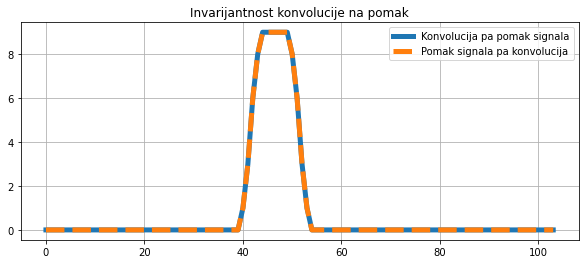

In [13]:
# Invarijantnost na pomak

# Ulazni signal i kernel
x = np.zeros(100)
x[30:40] = 1  # pravokutni impuls

x_shifted = np.roll(x, 10)

h = np.array([1, 2, 3, 2, 1])

# Konvolucija s originalnim signalom pa onda pomicanje
y1 = convolve(x, h, mode='full')
y1 = np.roll(y1, 10)

# Konvolucija s pomaknutim signalom
y2 = convolve(x_shifted, h, mode='full')

# Prikaz rezultata
plt.figure(figsize=(10, 4))
plt.plot(y1, label='Konvolucija pa pomak signala', color='tab:blue', linewidth=5)
plt.plot(y2, label='Pomak signala pa konvolucija', color='tab:orange', linestyle='--', linewidth=5)
plt.title("Invarijantnost konvolucije na pomak")
plt.legend()
plt.grid()
plt.show()


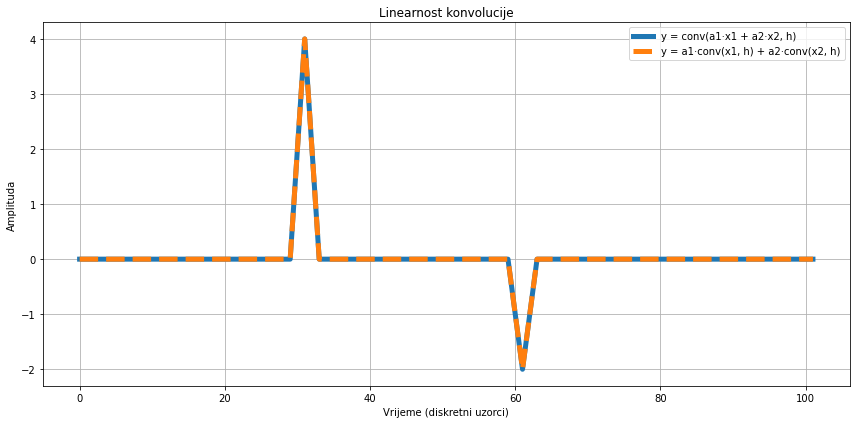

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve

# 1. Dva impulsa
x1 = np.zeros(100)
x1[30] = 1  # impuls na poziciji 30

x2 = np.zeros(100)
x2[60] = 1  # impuls na poziciji 60

# 2. Koeficijenti
a1, a2 = 2, -1

# 3. Kernel (filtar)
h = np.array([1, 2, 1])  

# 4. Pojedinačne konvolucije
y1 = convolve(x1, h, mode='full')
y2 = convolve(x2, h, mode='full')

# 5. Linearna kombinacija rezultata konvolucije
y_sum = a1 * y1 + a2 * y2

# 6. Kombinacija ulaza, pa onda konvolucija
x_comb = a1 * x1 + a2 * x2
y_comb = convolve(x_comb, h, mode='full')

# 7. Usporedba rezultata
plt.figure(figsize=(12, 6))
plt.plot(y_comb, label='y = conv(a1·x1 + a2·x2, h)', color='tab:blue', linewidth=5)
plt.plot(y_sum, '--', label='y = a1·conv(x1, h) + a2·conv(x2, h)', color='tab:orange', linewidth=5)
plt.title("Linearnost konvolucije")
plt.xlabel("Vrijeme (diskretni uzorci)")
plt.ylabel("Amplituda")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


***

## Svojstva konvolucije: dokazi


### Komutativnost

$$
\begin{aligned}
(x*h)[n] 
&= \sum_{k=-\infty}^{\infty} x[k]\,h[n-k] \\
m = n - k \rightarrow
k= n - m \\
&= \sum_{m=-\infty}^{\infty} x[n-m]\,h[m] \\
&= \sum_{m=-\infty}^{\infty} h[m]\,x[n-m] \\
&= (h*x)[n]
\end{aligned}
$$

$$
x*h = h*x
$$

---

### Asocijativnost

$$
\begin{aligned}
((g*h)*x)[n] 
&= \sum_{k=-\infty}^{\infty} (g*h)[k]\,x[n-k] \\
&= \sum_{k=-\infty}^{\infty} \left( \sum_{m=-\infty}^{\infty} g[m]\,h[k-m] \right) x[n-k] \\
&= \sum_{m=-\infty}^{\infty} g[m] \sum_{k=-\infty}^{\infty} h[k-m]\,x[n-k] \\
r = k - m \rightarrow k= r + m\\
&= \sum_{m=-\infty}^{\infty} g[m] \sum_{r=-\infty}^{\infty} h[r]\,x[n-(r+m)] \\
&= \sum_{m=-\infty}^{\infty} g[m]\,(h*x)[n-m] \\
&= (g*(h*x))[n]
\end{aligned}
$$

$$
(g*h)*x = g*(h*x)
$$

---

### Distributivnost

$$
\begin{aligned}
(h*(x_1 + x_2))[n] 
&= \sum_{k=-\infty}^{\infty} h[k]\,(x_1 + x_2)[n-k] \\
&= \sum_{k=-\infty}^{\infty} h[k]\,(x_1[n-k] + x_2[n-k]) \\
&= \sum_{k=-\infty}^{\infty} h[k]\,x_1[n-k] 
+ \sum_{k=-\infty}^{\infty} h[k]\,x_2[n-k] \\
&= (h*x_1)[n] + (h*x_2)[n]
\end{aligned}
$$

$$
h*(x_1 + x_2) = h*x_1 + h*x_2
$$